# Week 8 · Reports and screens

The same records serve different people. This week you decide who sees what, put the most urgent food first, and build a small menu.

| | |
|---|---|
| **This week's question** | Who needs which information, and how do we keep numbers honest and private data private? |
| **Python you will learn** | `sorted()` with a named key function, choosing fields from a dictionary, lining up text with f-strings, a menu function that returns text |
| **Principle 8** | **Right information for the right person.** Honest numbers, private data kept private. |
| **Part you build** | `public_row` (the public board), `most_urgent_first` (a sort key) and `handle_choice` (the menu) |

*Campus FoodBridge is fictional. All organisations, people and numbers are invented.*

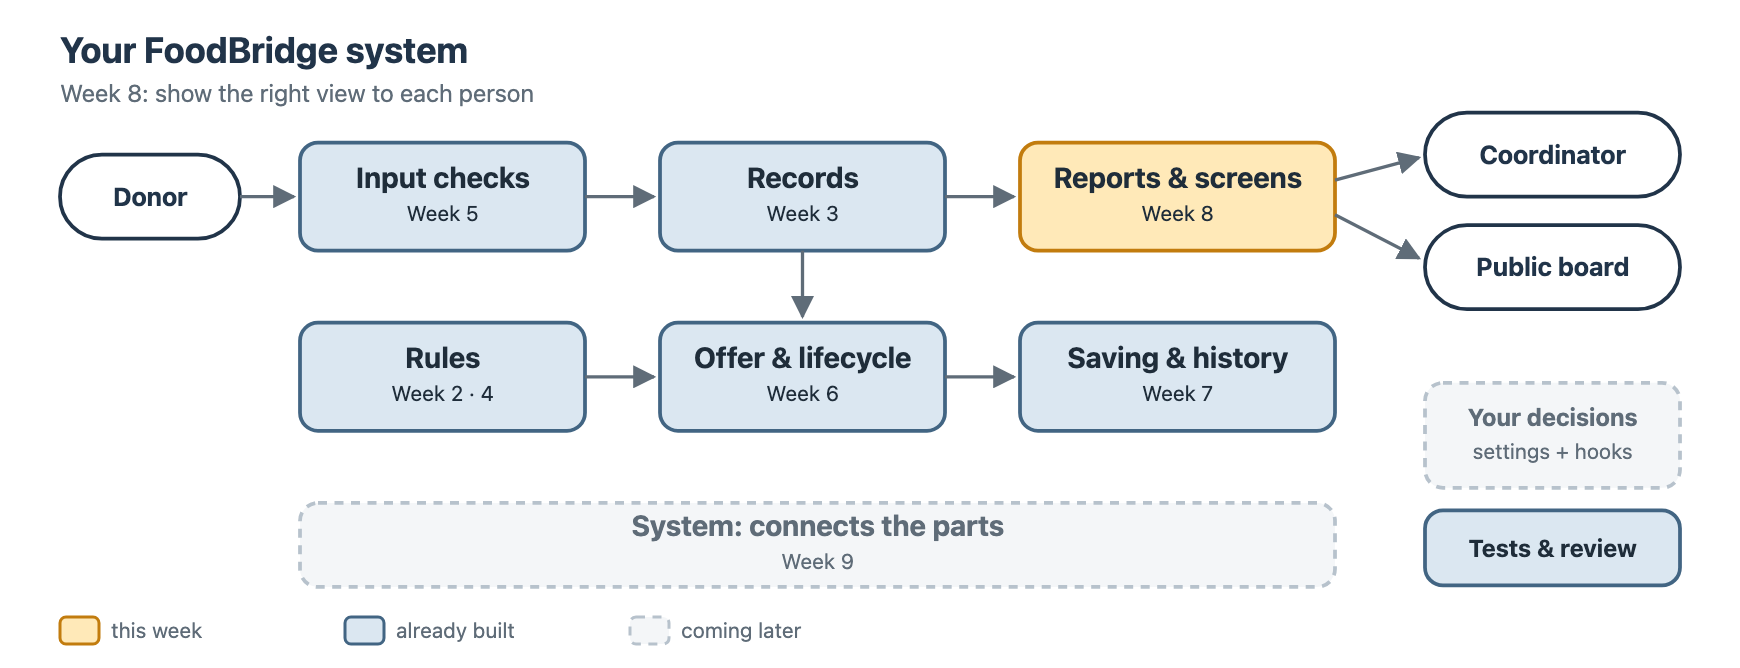

## Before you start

1. Click **Copy to Drive** (or **File → Save a copy in Drive**), then work in your copy.
2. Run the setup cell. Run it again after a runtime restart.
3. ⭐ = core for everyone, ⭐⭐ = optional stretch.

In [ ]:
# @title ▶ Run this cell first (setup) — it prepares the FoodBridge system
# It unpacks the course system that is stored inside this notebook.
# No internet, no installation. Run it again after Colab restarts.
import base64, hashlib, importlib, io, os, sys, zipfile
_KIT_VERSION = "2026.11.3"
_KIT_SHA = "9a7f0e70ab94bb1480312c1ccc2cd08ea21038ab8fa51cc0adbfe520961d0844"
_KIT_ZIP = "..."

def _prepare_kit():
    data = base64.b64decode(_KIT_ZIP)
    if hashlib.sha256(data).hexdigest() != _KIT_SHA:
        raise RuntimeError("This notebook's course files are damaged. Download a fresh copy.")
    marker = os.path.join("foodbridge_kit", ".kit_version")
    current = open(marker).read().strip() if os.path.exists(marker) else ""
    keep = ("foodbridge_kit/my_settings.py", "foodbridge_kit/my_rules.py")
    with zipfile.ZipFile(io.BytesIO(data)) as archive:
        for name in archive.namelist():
            if current == _KIT_VERSION and os.path.exists(name):
                continue                      # already up to date
            if name in keep and os.path.exists(name):
                continue                      # never overwrite your own files
            os.makedirs(os.path.dirname(name), exist_ok=True)
            with open(name, "wb") as target:
                target.write(archive.read(name))
    with open(marker, "w") as file:
        file.write(_KIT_VERSION)
    folder = os.path.abspath("foodbridge_kit")
    if folder not in sys.path:
        sys.path.insert(0, folder)
    for module in [m for m in sys.modules if m == "foodbridge" or m.startswith("foodbridge.")]:
        del sys.modules[module]             # load the fresh copy

_prepare_kit()
import foodbridge as bridge
print("✅ FoodBridge system ready (version " + bridge.KIT_VERSION + "). You can continue.")


## Class warm-up · Research 6 exchange (10 min)

In groups of three, share the AI answer you checked.

1. Which claim did you accept, which did you correct, and which would you still ask about?
2. Which original source did you use? How long did the check take?
3. What could have gone wrong if nobody had checked? Who would have been hurt?

📝 **One checking habit I will use from now on:**

## Session 1 · Learn: views, order and honest numbers (30 min)

### The idea: the right information for the right person

Think of a hospital. The doctor sees your full file: your name, phone number and history. The screen in the waiting room shows only your ticket number and the room to go to. It is the same data, but a different **view**. Each view is designed for one person and one task, and it leaves out what that person should not see.

Our system already has two views:

| View | Who reads it | What it needs | What it must not show |
|---|---|---|---|
| Coordinator view | the coordinator | every open offer, with the donor and the **contact**, to arrange pickups | nothing is hidden |
| Public board | anyone: students, donors, partners | what food is moving, and how much | contact details |

A view must also be **honest**. Run the cell and read the numbers.

In [ ]:
day = bridge.System()
day.run_day(show=False)
print(day.summary_text())

100 portions were **offered**, 48 were **picked up** and 18 were **delivered**. These are three stages of the same food: F002's 18 portions are inside all three numbers. Adding them (166) counts the same portions three times. They are different measures, so they must never be added together. The unit is **portions**, not "meals": the system does not know how many people ate.

🤔 A sponsor asks: *"How much food did you rescue today?"* Which number would you give, and what would you say with it?

**My answer:** …

### 1 · `sorted()` makes a new list in order

🤔 **Predict** the third line before you run the cell.

In [ ]:
marks = [72, 45, 90, 61]
print(sorted(marks))
print(sorted(marks, reverse=True))
print(marks)

names = ["Sokha", "Dara", "Vanna"]
print(sorted(names))

**Prediction:** …  **Result:** …

- `sorted` returns a **new** list. The original list does not change.
- `reverse=True` puts the largest first.
- This is useful for views: the coordinator and the public board can sort the same records in different orders without disturbing each other.

### 2 · Sorting records with a named key function

Python cannot guess how to order dictionaries: by name? by mark? You tell it with a **key function**. It receives one item and returns the value to sort by.

In [ ]:
students = [{"name": "Sokha", "mark": 72},
            {"name": "Dara", "mark": 90},
            {"name": "Vanna", "mark": 61}]

def by_mark(student):
    return student["mark"]

for student in sorted(students, key=by_mark):
    print(student["name"], student["mark"])

Write `key=by_mark` **without** `( )`. You give `sorted` the function itself, and `sorted` calls it once for each student. A good name says the order: `by_mark`, `most_urgent_first`.

🤔 **Predict:** with `reverse=True` added, who comes first? Change the cell and check.

**Prediction:** …  **Result:** …

### 3 · Choosing fields from a dictionary

A public view is a **smaller copy** of a record. The safe way to build it is to start empty and copy only the fields on an **allowed list**. (The phone number is invented.)

🤔 **Predict:** the last two lines add a new private field. Will the notice board show it?

In [ ]:
student = {"name": "Dara", "phone": "012 000 111", "mark": 90, "class": "MIS1"}
NOTICE_BOARD_FIELDS = ["name", "class"]

def notice_board_row(student):
    row = {}
    for field in NOTICE_BOARD_FIELDS:
        row[field] = student[field]
    return row

print(notice_board_row(student))

student["home_address"] = "Street 271"      # someone adds a new private field later
print(notice_board_row(student))

**Prediction:** …  **Result:** …

The other way, copying everything and then deleting the private fields, is risky. When someone adds a new private field later, it appears on the board until somebody notices. With an allowed list, a new field stays hidden until a person **decides** to show it.

### 4 · Lining up columns with f-strings

Inside `{ }`, a colon sets the width: `<` puts the value on the left, `>` on the right. Put text on the left and numbers on the right, so the digits line up.

In [ ]:
food = "Bread rolls"
portions = 30
print(f"[{food:<12}]")       # text on the left, 12 characters wide
print(f"[{portions:>4}]")    # number on the right, 4 characters wide

print(f"{food:<12} {portions:>4} portions")
food = "Rice"
portions = 3
print(f"{food:<12} {portions:>4} portions")

### 5 · A menu function that returns text

A menu has two jobs: **asking** the person what they want, and **deciding** what to show. Keep the two jobs apart. The deciding part is a normal function that **returns** text. Then you can test it without typing, and the same function can serve a text menu, a check or a web page.

In [ ]:
def library_answer(choice):
    if choice == "1":
        return "Open 8:00-17:00, Monday to Saturday."
    if choice == "2":
        return "You can borrow 3 books for 14 days."
    if choice == "q":
        return "Goodbye!"
    return "Unknown choice " + repr(choice) + ". Please type 1, 2 or q."

print(library_answer("1"))
print(library_answer("7"))

`repr(choice)` shows the text in quotes, so even an empty answer or a space is visible.

🤔 What would `library_answer("7")` return without the last `return` line? What would the person see?

**My answer:** …

### 6 · FoodBridge: urgent food first, lined up

The same ideas on the sample records: a named key function, then lined-up columns.

In [ ]:
def by_hours_left(record):
    return record["hours_left"]

for record in sorted(bridge.sample_records(), key=by_hours_left):
    hours = record["hours_left"]
    print(f"{record['id']:<5} {record['food']:<26} {hours:>3} hours left")

## Session 2 · Practise and judge (60 min)

### ⭐ P1 · Sort the shop

Write `by_price(product)`. Print the products cheapest first, then most expensive first.

In [ ]:
products = [{"name": "Soap", "price_usd": 1.5},
            {"name": "Rice 5 kg", "price_usd": 6.0},
            {"name": "Pen", "price_usd": 0.5},
            {"name": "Notebook", "price_usd": 1.2}]

def by_price(product):
    # TODO: return the value to sort by
    return 0

print("Cheapest first:")
for product in sorted(products, key=by_price):
    print(f"  {product['name']:<10} {product['price_usd']:>5} USD")

print("Most expensive first:")
# TODO: the same loop, with reverse=True

<details><summary>Show a possible answer</summary>

```python
def by_price(product):
    return product["price_usd"]

for product in sorted(products, key=by_price, reverse=True):
    print(f"  {product['name']:<10} {product['price_usd']:>5} USD")
```

Cheapest first: Pen, Notebook, Soap, Rice 5 kg. With `reverse=True` the order is the other way round. The name `price_usd` carries the unit (Principle 1).

</details>

### ⭐ P2 · Largest offers first

The team leader plans the vehicles and wants to see the biggest offers first. Write `by_portions(record)` and print the sample records, largest first. Expected order: F003, F001, F002, F004.

In [ ]:
records = bridge.sample_records()

def by_portions(record):
    # TODO: return the number to sort by
    return 0

for record in sorted(records, key=by_portions, reverse=True):
    print(record["id"], record["portions"], "portions")

🤔 Is "largest first" also a good order for the volunteers? Look at F004: its status and its hours left.

**My answer:** …

<details><summary>Show a possible answer</summary>

```python
def by_portions(record):
    return record["portions"]
```

For planning vehicles, largest first is useful. For the volunteers it is risky: F004 is approved and still waiting, with only 4 hours left, but it is last in this list. The right order depends on **who** reads the list and **what** they must do next.

</details>

### ⭐ P3 · What does a volunteer need?

A volunteer collects food from the donor and takes it to the partner. Choose the fields a volunteer needs, and write `volunteer_row(record)` with an allowed list. Then explain one field you left out.

In [ ]:
VOLUNTEER_FIELDS = ["id", "food"]       # TODO: add the other fields a volunteer needs

def volunteer_row(record):
    row = {}
    # TODO: copy only the fields in VOLUNTEER_FIELDS from record into row
    return row

print(volunteer_row(bridge.sample_records()[3]))

**One field I left out, and why:** …

<details><summary>Show a possible answer</summary>

```python
VOLUNTEER_FIELDS = ["id", "donor", "food", "portions", "hours_left", "partner"]

def volunteer_row(record):
    row = {}
    for field in VOLUNTEER_FIELDS:
        row[field] = record[field]
    return row
```

One reasonable choice leaves out `contact`: the coordinator arranges the pickup, so the donor's email does not need to be on every volunteer's phone. Another team could decide differently. That is the point: it is a **decision**, and it belongs in a decision log.

</details>

### ⭐ P4 · Repair the dashboard line

This code adds three different measures into one number. Replace the last line with **three lined-up lines**, one for each measure, with the unit. Expected:

```text
Portions offered:    100
Portions picked up:   48
Portions delivered:   18
```

In [ ]:
records = bridge.sample_records()
offered = 0
picked_up = 0
delivered = 0
for record in records:
    offered += record["portions"]
    if record["status"] in ["picked_up", "delivered"]:
        picked_up += record["portions"]
    if record["status"] == "delivered":
        delivered += record["portions"]

print("Food rescued:", offered + picked_up + delivered)   # TODO: replace with three lined-up lines

🤔 Why is 166 meaningless? Which offer is counted three times, and which offer is counted although its food never moved?

**My answer:** …

<details><summary>Show a possible answer</summary>

```python
print(f"Portions offered:   {offered:>4}")
print(f"Portions picked up: {picked_up:>4}")
print(f"Portions delivered: {delivered:>4}")
```

F002's 18 portions are in all three numbers, and F001's 30 are in two. F003's 40 portions of bananas were rejected and never left the market, but they are in "offered", so they are inside the 166 too. "Food rescued: 166" sounds impressive and means nothing. Three honest numbers, each with its unit, let people see the whole story.

</details>

### ⭐⭐ S1 · Sort by two things

When two offers have the same hours left, the coordinator wants the larger one first. A key function can return a **pair** of values: `(first, second)`. Python compares the first values, and uses the second only when the first are equal. A minus sign puts larger portions first.

In [ ]:
offers = [{"id": "A", "hours_left": 4, "portions": 12},
          {"id": "B", "hours_left": 2, "portions": 18},
          {"id": "C", "hours_left": 4, "portions": 30}]

def urgent_then_largest(record):
    # TODO: return (record["hours_left"], -record["portions"])
    return 0

for record in sorted(offers, key=urgent_then_largest):
    print(record["id"], record["hours_left"], "hours,", record["portions"], "portions")   # expected: B, C, A

### ⚖️ Good or risky?

The coordinator asked an AI assistant: *"Make a dashboard for the public screen in the canteen."* It gave you **Version A**. **Version B** is a rewrite. Both run without errors.

**Version A**

```python
def by_food_name(record):
    return record["food"]

def dashboard(records):
    offered = 0
    picked_up = 0
    delivered = 0
    for record in records:
        offered += record["portions"]
        if record["status"] == "picked_up":
            picked_up += record["portions"]
        if record["status"] == "delivered":
            delivered += record["portions"]
    lines = [f"Meals served: {offered + picked_up + delivered}"]
    for record in sorted(records, key=by_food_name):
        lines.append(f"{record['food']:<26} {record['portions']:>4}  {record['contact']}")
    return "\n".join(lines)
```

On the four sample records, Version A shows:

```text
Meals served: 148
Bananas                      40  greenstall@example.org
Bread rolls                  30  sunrise@example.org
Fried rice boxes             18  canteen@example.org
Vegetable curry with rice    12  lotus@example.org
```

**Version B**

```python
def by_hours_left(record):
    return record["hours_left"]

def public_board(records):
    delivered = 0
    for record in records:
        if record["status"] == "delivered":
            delivered += record["portions"]
    lines = [f"Portions delivered so far: {delivered}"]
    for record in sorted(records, key=by_hours_left):
        if record["status"] not in ["rejected", "cancelled"]:
            portions = record["portions"]
            lines.append(f"{record['food']:<26} {portions:>4} portions  {record['status']}")
    return "\n".join(lines)
```

```text
Portions delivered so far: 18
Fried rice boxes             18 portions  delivered
Vegetable curry with rice    12 portions  approved
Bread rolls                  30 portions  picked_up
```

(`"\n".join(lines)` joins a list of lines into one text, with a new line between them.)

Use **Principle 8 (right information for the right person)**. Find **at least three** problems in Version A. For each one, name the offer or the person who would be harmed.

📝 **Problems I found in Version A:**

1.
2.
3.

<details><summary>Instructor's view</summary>

1. **A dishonest number.** "Meals served: 148" adds three different measures: all portions offered (100), portions with status picked up (30) and portions delivered (18). F001's bread and F002's rice are each counted twice. F003's 40 portions of bananas were rejected and never left the market, but they are in the 148. The unit is wrong too: the system counts **portions**, not meals, and it cannot know what was "served". The honest number is **18 portions delivered**. Donors and sponsors who plan with 148 are misled, and the team loses trust as soon as someone checks.
2. **Private data on a public screen.** Every donor's contact email is shown to anyone in the canteen. Sunrise Bakery, Campus Canteen, Green Market Stall and Lotus Cafe could receive spam or unwanted calls, and some may stop donating.
3. **Urgent food is buried.** Alphabetical order puts the rejected bananas at the top and F004 (vegetable curry, 4 hours left, still waiting for pickup) at the bottom. A volunteer who reads from the top may miss it, and the Old Market Elders' Group may not get its 12 portions before the food spoils.
4. **Rejected food is shown as if it were available,** and there is no status column. People may ask for bananas that are not coming.

Version B shows one honest measure with its unit, no private fields, no rejected offers, and the fewest hours left first. AI dashboards often reach for one big, impressive number. Ask what it measures, and whether a person could check it.

</details>

## Session 3 · Build your part: the public board and the menu (60–80 min)

Three small parts decide what people see:

- `public_row` decides which fields of a record appear on the **public board**, which anyone can read.
- `most_urgent_first` is a sort key, so the most urgent food is at the top, where a volunteer looks first.
- `handle_choice` decides what the **menu** shows for each choice. The kit supplies the loop that asks the questions; your function gives the answers.

### Part 1 · `public_row`

Return a new dictionary with **only** the fields in `PUBLIC_FIELDS`. The check uses **your** `PUBLIC_FIELDS`, so it still passes after you change this decision.

In [ ]:
PUBLIC_FIELDS = ["id", "food", "category", "portions", "status"]   # 🧭 your decision (end of session)

def public_row(record):
    # TODO 1: start with an empty dictionary called row
    # TODO 2: for each field in PUBLIC_FIELDS, copy record[field] into row
    # TODO 3: return row
    return None

In [ ]:
bridge.check("public_row", public_row, {"PUBLIC_FIELDS": PUBLIC_FIELDS})

### Part 2 · `most_urgent_first`

Return the number to sort by: the offer's hours left. Fewer hours left means more urgent, so earlier in the list. The check sorts the four sample records with your key and expects F002 (2 hours), F004 (4), F001 (5), F003 (20).

`REPORT_SORT` is a setting: it tells the system how to order **both** views. `"urgency"` uses the same idea as your key.

In [ ]:
REPORT_SORT = "urgency"     # 🧭 your decision: "urgency", "portions" or "id"

def most_urgent_first(record):
    # TODO: return the record's hours left
    return 0

In [ ]:
bridge.check("most_urgent_first", most_urgent_first)

### Part 3 · `handle_choice`

Return the text for each choice. **Return** it; do not print it.

| Choice | Return |
|---|---|
| `"1"` | `system.report("coordinator")` |
| `"2"` | `system.report("public")` |
| `"3"` | `system.summary_text()` |
| `"4"` | `system.history_text()` |
| `"q"` | `"Goodbye!"` |
| anything else | a helpful message, such as `"Unknown choice 'x'. Please type 1-6 or q."` |

The kit's menu handles choices 5 (add an offer) and 6 (move an offer) itself, because they need several questions.

In [ ]:
def handle_choice(choice, system):
    # TODO 1: return the text for "1", "2", "3", "4" and "q" (see the table)
    # TODO 2: for anything else, return a helpful message
    # Tip: choice.strip().lower() also accepts " Q " from a person in a hurry.
    return "Not done yet."

In [ ]:
bridge.check("handle_choice", handle_choice)

### Part 4 · Plug in: your board, your order, your menu

`public_row` is a **hook**: the system calls your function for every row of the public board. If it is not finished yet, the system warns you and uses its default, so the board still works.

In [ ]:
MY_SETTINGS = {"PUBLIC_FIELDS": PUBLIC_FIELDS, "REPORT_SORT": REPORT_SORT}
my_system = bridge.System(MY_SETTINGS, hooks={"public_row": public_row})
my_system.run_day(show=False)
print(my_system.report("public"))

Now a volunteer's list, sorted with **your** key and lined up with f-strings:

In [ ]:
for record in sorted(my_system.records(), key=most_urgent_first):
    hours = record["hours_left"]
    print(f"{record['id']:<5} {record['food']:<26} {hours:>3} hours left  {record['status']}")

Finally, the menu. `script=` types the answers for you: first 1, then 2, then q. The kit's loop asks; **your** `handle_choice` answers.

In [ ]:
bridge.run_menu(my_system, script=["1", "2", "q"], handle=handle_choice)
print("(The menu stopped after q.)")

In [ ]:
# Try the real menu: remove the # at the start of the last line, run the cell, and type your choices.
# Type q to stop. Then put the # back, so that
# "Runtime → Restart session and run all" never waits for you.
# bridge.run_menu(my_system, handle=handle_choice)

### 🧭 Your decision · who sees what, and in which order?

You make two decisions this week:

- **`PUBLIC_FIELDS`:** which fields anyone can see. Example tradeoff: a donor may *want* public recognition ("Thank you, Sunrise Bakery!"). Showing the donor's name needs that donor's agreement. Showing the **contact** is never acceptable on a public board.
- **`REPORT_SORT`:** the order of both views: `"urgency"` (fewest hours left first), `"portions"` (largest first) or `"id"` (oldest first).

1. Change `PUBLIC_FIELDS` in Part 1 and `REPORT_SORT` in Part 2. You may keep the defaults if you can explain why.
2. Rerun Parts 1, 2 and 4. The checks still pass, because they use your choices.
3. Run the cell below: it shows the coordinator view in your order and reminds you about private fields.

In [ ]:
if "contact" in PUBLIC_FIELDS:
    print("⚠️ The public board shows contact details. Donors never agreed to this.")
if "donor" in PUBLIC_FIELDS:
    print("Note: the public board shows donor names. Did every donor agree?")
print("Public fields:", PUBLIC_FIELDS)
print("Report order: ", REPORT_SORT)
print()
print(my_system.report("coordinator"))

📝 **Decision log · Week 8**

| | |
|---|---|
| **My choice** | PUBLIC_FIELDS = … ; REPORT_SORT = … |
| **An alternative I considered** | |
| **Why I chose it** | |
| **Who is affected (the tradeoff)** | who is protected, and who sees less: |

### ⭐⭐ Stretch · a choice for volunteers

Write `volunteer_list(system)` that returns one lined-up line for each **approved** offer, most urgent first, with the partner and without contact details. Then add `if choice == "v": return volunteer_list(system)` to your `handle_choice`. The kit's menu passes every choice except 5 and 6 to your function, so `bridge.run_menu(my_system, script=["v", "q"], handle=handle_choice)` will show your list.

In [ ]:
def volunteer_list(system):
    lines = []
    # TODO: for each approved record, most urgent first, add one lined-up line (no contact!)
    return "\n".join(lines)

print(volunteer_list(my_system))

## Finish

- [ ] I shared my Research 6 check in the warm-up.
- [ ] I can explain why offered, picked up and delivered must never be added together.
- [ ] I found at least three problems in the AI dashboard, and named who would be harmed.
- [ ] `public_row`, `most_urgent_first` and `handle_choice` pass every check, and my public board uses `public_row`.
- [ ] My decision log explains `PUBLIC_FIELDS` and `REPORT_SORT`, including who is protected.

There is **no new research task** this week: Research 6 was the last one. Weeks 9 and 10 focus on the final project.

**Next week:** you put every part together into one system with all your settings, and start your final project.